In [20]:
import re
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
text="Mr.Darcy was the best protagonist to a novel ever written. He was a socially awkward man. His manner came off as rude and arrogant. However, he was a very loving person with a pride issue. He loved his sister very dearly."


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [13]:
#1. make lowercase and remove punctuation
text=text.lower()
re.sub(r"[.,]","",text)
#2. Tokenise the text into words and sentences
from nltk.tokenize import word_tokenize
words=word_tokenize(text)
from nltk.tokenize import sent_tokenize
sentences=sent_tokenize(text)

In [16]:
#3. Split using split() and word_tokenize() and compare how Python split and NLTK’s
split_words=text.split()
print(words)
print(split_words)
# 4.
from nltk.corpus import stopwords
stop_words=stopwords.words("english")
words=[word for word in words if word not in stop_words]
print(words)
#5
from nltk.probability import FreqDist
fd=FreqDist(words)
print(fd)
print(fd.most_common())

['mr.darcy', 'best', 'protagonist', 'novel', 'ever', 'written', '.', 'socially', 'awkward', 'man', '.', 'manner', 'came', 'rude', 'arrogant', '.', 'however', ',', 'loving', 'person', 'pride', 'issue', '.', 'loved', 'sister', 'dearly', '.']
['mr.darcy', 'was', 'the', 'best', 'protagonist', 'to', 'a', 'novel', 'ever', 'written.', 'he', 'was', 'a', 'socially', 'awkward', 'man.', 'his', 'manner', 'came', 'off', 'as', 'rude', 'and', 'arrogant.', 'however,', 'he', 'was', 'a', 'very', 'loving', 'person', 'with', 'a', 'pride', 'issue.', 'he', 'loved', 'his', 'sister', 'very', 'dearly.']
['mr.darcy', 'best', 'protagonist', 'novel', 'ever', 'written', '.', 'socially', 'awkward', 'man', '.', 'manner', 'came', 'rude', 'arrogant', '.', 'however', ',', 'loving', 'person', 'pride', 'issue', '.', 'loved', 'sister', 'dearly', '.']
<FreqDist with 23 samples and 27 outcomes>
[('.', 5), ('mr.darcy', 1), ('best', 1), ('protagonist', 1), ('novel', 1), ('ever', 1), ('written', 1), ('socially', 1), ('awkward'

In [21]:
#Ques 2
#1
tokens=re.findall(r"[a-zA-Z]+",text)
#2
tokens=[token for token in tokens if token not in stop_words]
#3
from nltk.stem import PorterStemmer
stemmer=PorterStemmer()
ps_words=[stemmer.stem(token)for token in tokens]
print(ps_words)
from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()
wnl_words=[lemmatizer.lemmatize(token)for token in tokens]
print(wnl_words)

['mr', 'darci', 'best', 'protagonist', 'novel', 'ever', 'written', 'he', 'social', 'awkward', 'man', 'hi', 'manner', 'came', 'rude', 'arrog', 'howev', 'love', 'person', 'pride', 'issu', 'he', 'love', 'sister', 'dearli']
['Mr', 'Darcy', 'best', 'protagonist', 'novel', 'ever', 'written', 'He', 'socially', 'awkward', 'man', 'His', 'manner', 'came', 'rude', 'arrogant', 'However', 'loving', 'person', 'pride', 'issue', 'He', 'loved', 'sister', 'dearly']


I would use lemmatizer over stemmer because stemmer cut words like his to hi , which is wrong in terms of context and model may interpret it completely differently.

In [22]:
text2=["The new smartphone has an excellent camera and long battery life.","The restaurant served delicious food with excellent service and friendly staff.","The electric car offers long battery range, fast charging, and modern design."]
from sklearn.feature_extraction.text import CountVectorizer
vectorizer=CountVectorizer()
bow=vectorizer.fit_transform(text2)
print(vectorizer.get_feature_names_out())
print(bow.toarray())

['an' 'and' 'battery' 'camera' 'car' 'charging' 'delicious' 'design'
 'electric' 'excellent' 'fast' 'food' 'friendly' 'has' 'life' 'long'
 'modern' 'new' 'offers' 'range' 'restaurant' 'served' 'service'
 'smartphone' 'staff' 'the' 'with']
[[1 1 1 1 0 0 0 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 1 0]
 [0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 1 0 1 1 1]
 [0 1 1 0 1 1 0 1 1 0 1 0 0 0 0 1 1 0 1 1 0 0 0 0 0 1 0]]


In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
X=tfidf.fit_transform(text2)
tf_words=tfidf.get_feature_names_out()
print(words)
print(X.toarray())

['an' 'and' 'battery' 'camera' 'car' 'charging' 'delicious' 'design'
 'electric' 'excellent' 'fast' 'food' 'friendly' 'has' 'life' 'long'
 'modern' 'new' 'offers' 'range' 'restaurant' 'served' 'service'
 'smartphone' 'staff' 'the' 'with']
[[0.34436003 0.20338458 0.26189468 0.34436003 0.         0.
  0.         0.         0.         0.26189468 0.         0.
  0.         0.34436003 0.34436003 0.26189468 0.         0.34436003
  0.         0.         0.         0.         0.         0.34436003
  0.         0.20338458 0.        ]
 [0.         0.19392047 0.         0.         0.         0.
  0.32833589 0.         0.         0.24970791 0.         0.32833589
  0.32833589 0.         0.         0.         0.         0.
  0.         0.         0.32833589 0.32833589 0.32833589 0.
  0.32833589 0.19392047 0.32833589]
 [0.         0.18814341 0.2422689  0.         0.31855448 0.31855448
  0.         0.31855448 0.31855448 0.         0.31855448 0.
  0.         0.         0.         0.2422689  0.31855448 

In [34]:
for i in range(3):
  scores=X.toarray()[i]
  top_indices=scores.argsort()[-3:][::-1]
  print([tf_words[j] for j in top_indices])


['smartphone', 'new', 'life']
['with', 'staff', 'service']
['range', 'modern', 'offers']


In [43]:
t1= """Artificial intelligence enables computers to learn from data.
AI is used in healthcare, finance, and autonomous vehicles.
Machine learning helps systems recognize patterns and make predictions.
AI can automate repetitive tasks and support decision making."""

t2 = """Blockchain is a decentralized technology for storing digital records.
It records transactions in a secure and transparent manner.
Blockchain is widely associated with cryptocurrencies.
It can also be used for supply chains and digital identity."""
txt1=t1.lower()
txt2=t2.lower()
txt1=re.findall(r"[a-zA-Z]+",txt1)
txt2=re.findall(r"[a-zA-Z]+",txt2)
set1=set(txt1)
set2=set(txt2)
jaccard=len(set1 & set2)/len(set1 | set2)
print(f"Jaccard Similarity:{jaccard}")


Jaccard Similarity:0.09259259259259259


In [44]:
from sklearn.metrics.pairwise import cosine_similarity
vecs=tfidf.fit_transform([t1,t2])
cos_sim=cosine_similarity(vecs[0:1],vecs[1:2])
print(f"Cosine Similarity:{cos_sim[0][0]}")

Cosine Similarity:0.14280407713795934


cosine because tf-idf also contains weights of the words and not just whether a word exists.

In [50]:
# Answer 5
reviews= [
    "The headphones have excellent sound quality and the battery lasts all day.",
    "I love these headphones. They are comfortable and the audio is fantastic.",
    "The headphones look good, but the sound quality is average.",
    "The battery is terrible and the headphones stopped working after a week.",
    "Very disappointing product. The audio is poor and the build quality feels cheap."
]
from textblob import TextBlob
blob=[TextBlob(review) for review in reviews]
for b in blob:
  print(f"polarity:{b.sentiment.polarity}")
  print(f"Subjectivity:{b.sentiment.subjectivity}")
res=[]
for b in blob:
  if b.sentiment.polarity>0:
    res.append("Positive")
  elif b.sentiment.polarity<0:
    res.append("Negative")
  else:
    res.append("Neutral")
print(res)

polarity:0.7
Subjectivity:0.7
polarity:0.43333333333333335
Subjectivity:0.7666666666666666
polarity:0.3166666666666667
Subjectivity:0.4666666666666666
polarity:-1.0
Subjectivity:1.0
polarity:-0.26000000000000006
Subjectivity:0.7366666666666667
['Positive', 'Positive', 'Positive', 'Negative', 'Negative']


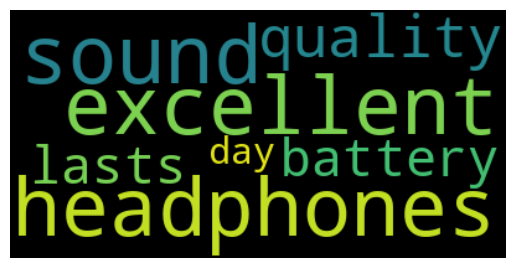

In [54]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
wc=[WordCloud().generate(review)for review in reviews]
plt.imshow(wc[0],interpolation="bilinear")
plt.axis("off")
plt.show()


In [60]:
# Question 6
text = """Artificial intelligence is changing the way people work and learn.
Machines can process large amounts of data and identify useful patterns.
Students use intelligent tools to understand difficult concepts and practice new skills.
Businesses use artificial intelligence to automate repetitive tasks and improve decision making.
Healthcare systems can use machine learning to support doctors and analyze medical information.
However, artificial intelligence should be developed responsibly and used carefully.
People must understand its limitations and avoid depending on technology for every decision.
The future of artificial intelligence will depend on collaboration between humans and intelligent machines.
With responsible development, artificial intelligence can create useful solutions for society."""
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer=Tokenizer()
tokenizer.fit_on_texts([text])
txt=tokenizer.texts_to_sequences([text])
print(txt)


[[2, 3, 17, 18, 7, 19, 8, 20, 1, 21, 9, 4, 22, 23, 24, 10, 25, 1, 26, 11, 27, 28, 5, 12, 29, 6, 13, 30, 31, 1, 32, 33, 34, 35, 5, 2, 3, 6, 36, 37, 38, 1, 39, 14, 40, 41, 42, 4, 5, 43, 44, 6, 45, 46, 1, 47, 48, 49, 50, 2, 3, 51, 52, 53, 54, 1, 55, 56, 8, 57, 13, 58, 59, 1, 60, 61, 15, 62, 16, 63, 14, 7, 64, 10, 2, 3, 65, 66, 15, 67, 68, 69, 1, 12, 9, 70, 71, 72, 2, 3, 4, 73, 11, 74, 16, 75]]


In [61]:
import numpy as np

input_sequences = []

for sentence in text.split("."):
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i+1])

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = np.array([
    np.pad(seq, (max_sequence_len - len(seq), 0))
    for seq in input_sequences
])

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

In [63]:
from keras.utils import to_categorical
total_words=len(tokenizer.word_index)+1
y = to_categorical(y, num_classes=total_words)

In [66]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense

model = Sequential([
    Embedding(total_words, 10, input_length=max_sequence_len - 1),
    LSTM(100),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()
model.fit(X, y, epochs=50, verbose=1)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.0000e+00 - loss: 4.3312
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0825 - loss: 4.3262
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0928 - loss: 4.3222
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1031 - loss: 4.3176
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1237 - loss: 4.3114
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1340 - loss: 4.3033
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1134 - loss: 4.2900
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1031 - loss: 4.2698
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1031 - loss: 4.2357
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1134 - loss: 4.1871
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1237 - loss: 4.1310
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1237 - loss: 4.08

In [67]:
seed_text = "artificial"

for _ in range(3):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    token_list = np.pad(
        token_list,
        (max_sequence_len - 1 - len(token_list), 0)
    )

    predicted = model.predict(np.array([token_list]), verbose=0)
    predicted_word = tokenizer.index_word[np.argmax(predicted)]

    seed_text += " " + predicted_word

print(seed_text)

artificial artificial artificial intelligence
